In [1]:
#Appel des librairies et du Dataframe
%config Completer.use_jedi = False
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, recall_score
from sklearn.metrics import classification_report
from sklearn.tree import plot_tree
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.feature_selection import VarianceThreshold,SelectKBest,f_classif, mutual_info_classif, RFE, RFECV
import joblib


df=pd.read_csv('001_df_processed.csv', low_memory=False)

#on extrait le pire accidenté pour caractériser l'accident et on ne garde qu'une ligne par accident
df['grav']=df['grav'].replace({1:0,2:3,3:2,4:1})
df = df.sort_values(by='grav')
df=df.drop_duplicates(subset='Num_Acc',keep='last')

df

,Num_Acc,grav,lum,agg,age,Casque,Ceinture,Dispositif_Enfant,Equipement_Réfléchissant,date,...,region_Corse,region_Grand Est,region_Hauts-de-France,region_Normandie,region_Nouvelle-Aquitaine,region_Occitanie,region_Outre-Mer,region_Pays de la Loire,region_Provence-Alpes-Côte d'Azur,region_Île-de-France
635724,200800028239,0.0,True,False,59.0,False,True,False,False,2008-05-22 23:15:00,...,False,False,False,False,False,True,False,False,False,False
207377,200600004519,0.0,False,False,42.0,False,True,False,False,2006-01-23 10:25:00,...,False,False,True,False,False,False,False,False,False,False
1436171,201300038029,1.0,False,True,27.0,False,True,False,False,2013-08-25 16:10:00,...,False,False,False,False,False,False,False,False,False,True
1450919,201300044882,1.0,False,True,77.0,False,False,False,False,2013-02-05 16:25:00,...,False,False,False,False,False,False,False,False,False,True
2393373,202100005516,1.0,False,True,82.0,False,False,False,True,2021-11-28 16:45:00,...,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2122076,201800048793,3.0,True,False,39.0,True,False,False,False,2018-01-08 17:52:00,...,False,False,False,False,True,False,False,False,False,False
1954924,201700035251,3.0,True,True,90.0,False,False,False,False,2017-12-29 18:00:00,...,False,False,False,False,False,False,False,True,False,False
1480522,201400000251,3.0,True,False,23.0,False,True,False,False,2014-06-14 04:30:00,...,False,False,True,False,False,False,False,False,False,False
1884466,201700003741,3.0,False,False,60.0,True,False,False,False,2017-06-03 14:45:00,...,False,False,False,False,False,False,False,False,True,False


In [3]:
#Pre processing restant

X = df.drop(columns=['grav','date','Num_Acc']) 
y = df['grav']

y=y.replace({0:'0',1:'0',2:'1',3:'1'}).astype(int)


X_train_save,X_test_save,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

y.value_counts()
X_train_save

,lum,agg,age,Casque,Ceinture,Dispositif_Enfant,Equipement_Réfléchissant,place_Arriere_Droit,place_Arriere_Gauche,place_Autre,...,region_Corse,region_Grand Est,region_Hauts-de-France,region_Normandie,region_Nouvelle-Aquitaine,region_Occitanie,region_Outre-Mer,region_Pays de la Loire,region_Provence-Alpes-Côte d'Azur,region_Île-de-France
972692,False,True,32.0,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
735227,False,True,15.0,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2307604,True,False,19.0,True,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2378050,False,False,18.0,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1540485,False,True,28.0,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1532342,False,True,22.0,False,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,False,False
1728083,False,True,48.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1907220,False,True,18.0,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1557934,False,True,31.0,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [3]:
#Reduction de dimensions, met 34 minutes avec n_jobs à 10

model = RandomForestClassifier(n_estimators=40,random_state=42, n_jobs=10,class_weight='balanced',criterion='entropy')


rfecv = RFECV(estimator=model, step=10, cv=3, scoring='recall', n_jobs=10)
rfecv.fit(X_train_save, y_train)


print("Nombre optimal de features : %d" % rfecv.n_features_)

features = [feature for feature, support in zip(rfecv.feature_names_in_, rfecv.support_) if support]
print(features)


X_train = rfecv.transform(X_train_save)
X_test = rfecv.transform(X_test_save)

"""Nombre optimal de features : 14
  ['lum', 'agg', 'age', 'senc_Repere_Croissant', 'prof_Pente', 'manv_Aucune_Manoeuvre', 'circ_Bidirectionnelle', 'surf_Glissant', 'col_2_Vehicules', 'catv_Voiture', 'atm_Faible', 'catr_Departementale', 'catr_Voix_Communale', 'region_Île-de-France']
""";

Nombre optimal de features : 14
['lum', 'agg', 'age', 'senc_Repere_Croissant', 'prof_Pente', 'manv_Aucune_Manoeuvre', 'circ_Bidirectionnelle', 'surf_Glissant', 'col_2_Vehicules', 'catv_Voiture', 'atm_Faible', 'catr_Departementale', 'catr_Voix_Communale', 'region_Île-de-France']


"Nombre optimal de caractéristiques : 9\n  ['agg', 'age', 'Ceinture', 'trajet_Loisirs', 'circ_Bidirectionnelle', 'obs_Vehicule', 'catr_Departementale', 'catr_Voix_Communale', 'region_Île-de-France']"

In [20]:
#_Machine learning. Met 3 minutes à n_jobs=10

model = RandomForestClassifier(n_estimators=50,random_state=42, n_jobs=10,class_weight='balanced',criterion='entropy')

param_grid = {
    'n_estimators': [100],
    'max_depth': [None],
    'class_weight' : ['balanced'],
    'criterion':['entropy']
}

# Création de l'objet GridSearchCV avec le classifieur, la grille d'hyperparamètres et le nombre de folds de validation croisée
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, n_jobs=10, scoring='recall')

# Lancement de la recherche de grille sur les données
grid_search.fit(X_train, y_train)

# Affichage des meilleurs hyperparamètres et du meilleur score
print("Meilleurs hyperparamètres :", grid_search.best_params_)
print("Meilleur score de validation :", grid_search.best_score_)

#model.fit(X_train_PCA, y_train)
model=grid_search.best_estimator_

"""Meilleurs hyperparamètres : {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}
Meilleur score de validation : 0.6380516790015198""";

Meilleurs hyperparamètres : {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}
Meilleur score de validation : 0.611644918169154


In [7]:
#_Test_et_résultats
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("___________________________________")
print(pd.crosstab(y_pred,y_test))


              precision    recall  f1-score   support

           0       0.72      0.73      0.72    128919
           1       0.63      0.62      0.62     95395

    accuracy                           0.68    224314
   macro avg       0.67      0.67      0.67    224314
weighted avg       0.68      0.68      0.68    224314

___________________________________
grav       0      1
row_0              
0      93839  36599
1      35080  58796


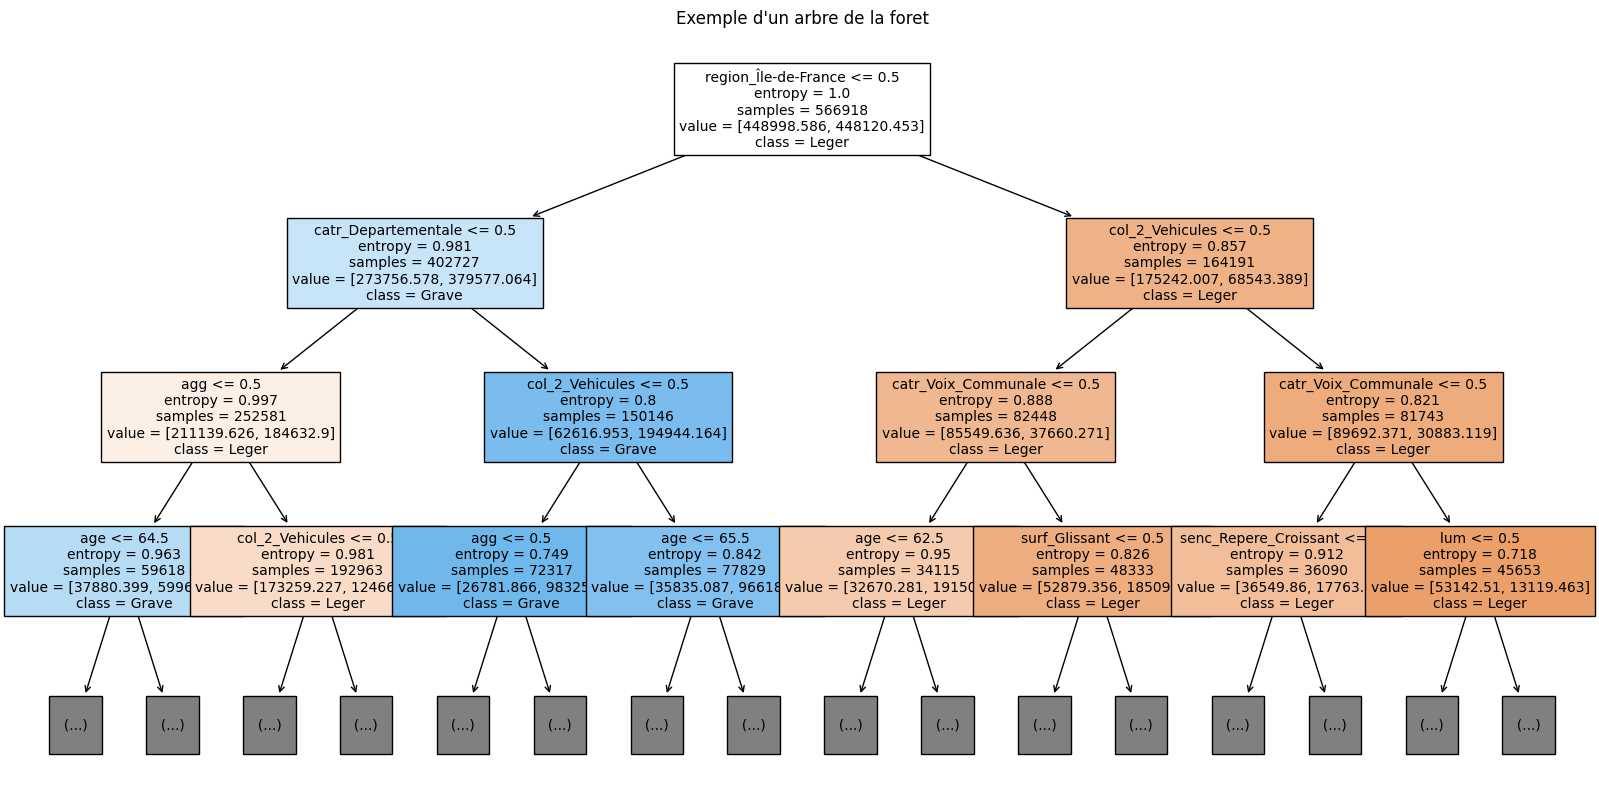

In [12]:
plt.figure(figsize=(20, 10))
plot_tree(model.estimators_[0], filled=True,max_depth=3,fontsize=10,feature_names=features,class_names=['Leger','Grave'])
plt.title("Exemple d'un arbre de la foret")
plt.show()


In [5]:
# Sauvegardes du modele et de la reduction de dimension
joblib.dump(model, 'random_forest_model.pkl')
joblib.dump(rfecv, 'rfecv_object.pkl')

['rfecv_object.pkl']

In [11]:
# Chargement du modèle sauvegardé
model = joblib.load('random_forest_model.pkl')
rfecv = joblib.load('rfecv_object.pkl')

X_train = rfecv.transform(X_train_save)
X_test = rfecv.transform(X_test_save)

print("Nombre de features : %d" % rfecv.n_features_)

features = [feature for feature, support in zip(rfecv.feature_names_in_, rfecv.support_) if support]
print(features)

print("Modèle", model)

Nombre de features : 14
['lum', 'agg', 'age', 'senc_Repere_Croissant', 'prof_Pente', 'manv_Aucune_Manoeuvre', 'circ_Bidirectionnelle', 'surf_Glissant', 'col_2_Vehicules', 'catv_Voiture', 'atm_Faible', 'catr_Departementale', 'catr_Voix_Communale', 'region_Île-de-France']
Modèle RandomForestClassifier(class_weight='balanced', criterion='entropy', n_jobs=10,
                       random_state=42)


In [ ]:
""" Voir pour utiliser :
skater
Lime
Shape

Tester un algo de NGboost au lieu de Randomforest

"""